In [16]:
import os
import pandas as pd

print("Files in data folder:")
print(os.listdir("data"))

Files in data folder:
['enron_spam_data.csv', 'SMSSpamCollection']


In [17]:
import pandas as pd
import os

print(os.listdir("data"))

['enron_spam_data.csv', 'SMSSpamCollection']


In [18]:
import pandas as pd

df_email = pd.read_csv("data/enron_spam_data.csv")

print("Dataset shape:", df_email.shape)
print("\nColumn names:")
print(df_email.columns.tolist())

print("\nFirst five rows:")
display(df_email.head())

Dataset shape: (33716, 5)

Column names:
['Message ID', 'Subject', 'Message', 'Spam/Ham', 'Date']

First five rows:


,Message ID,Subject,Message,Spam/Ham,Date
0,0,christmas tree farm pictures,NaN,ham,1999-12-10
1,1,"vastar resources , inc .","gary , production from the high island larger ...",ham,1999-12-13
2,2,calpine daily gas nomination,- calpine daily gas nomination 1 . doc,ham,1999-12-14
3,3,re : issue,fyi - see note below - already done .\nstella\...,ham,1999-12-14
4,4,meter 7268 nov allocation,fyi .\n- - - - - - - - - - - - - - - - - - - -...,ham,1999-12-14


In [1]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [19]:
# Load the Email Spam Dataset
df_email = pd.read_csv("data/enron_spam_data.csv")

df_email = df_email[["Subject", "Message", "Spam/Ham"]].copy()

df_email["Subject"] = df_email["Subject"].fillna("")
df_email["Message"] = df_email["Message"].fillna("")

df_email["message"] = (
    df_email["Subject"] + " " + df_email["Message"]
).str.strip()

df_email = df_email.rename(columns={"Spam/Ham": "label"})
df_email["label"] = df_email["label"].str.lower().str.strip()

df_email = df_email[df_email["label"].isin(["ham", "spam"])]
df_email = df_email[df_email["message"] != ""]
df_email = df_email.drop_duplicates(subset=["message", "label"])

df = df_email[["label", "message"]].copy()

print("Email dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df["label"].value_counts())

display(df.head())

Email dataset loaded successfully!
Dataset shape: (30462, 2)
label
ham     15910
spam    14552
Name: count, dtype: int64


,label,message
0,ham,christmas tree farm pictures
1,ham,"vastar resources , inc . gary , production fro..."
2,ham,calpine daily gas nomination - calpine daily g...
3,ham,re : issue fyi - see note below - already done...
4,ham,meter 7268 nov allocation fyi .\n- - - - - - -...


In [3]:
# Explore the dataset

print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df["label"].value_counts())

Dataset Shape:
(5572, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB

Missing Values:
label      0
message    0
dtype: int64

Label Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [20]:
# Check and clean the email dataset

print("Rows before cleaning:", len(df))

df = df.dropna()
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[df["label"].isin(["ham", "spam"])]
df = df[df["message"] != ""]
df = df.drop_duplicates(subset=["message", "label"])

print("Rows after cleaning:", len(df))
print("\nMissing values:")
print(df.isnull().sum())

print("\nEmail label distribution:")
print(df["label"].value_counts())

display(df.head())

Rows before cleaning: 30462
Rows after cleaning: 30462

Missing values:
label      0
message    0
dtype: int64

Email label distribution:
label
ham     15910
spam    14552
Name: count, dtype: int64


,label,message
0,ham,christmas tree farm pictures
1,ham,"vastar resources , inc . gary , production fro..."
2,ham,calpine daily gas nomination - calpine daily g...
3,ham,re : issue fyi - see note below - already done...
4,ham,meter 7268 nov allocation fyi .\n- - - - - - -...


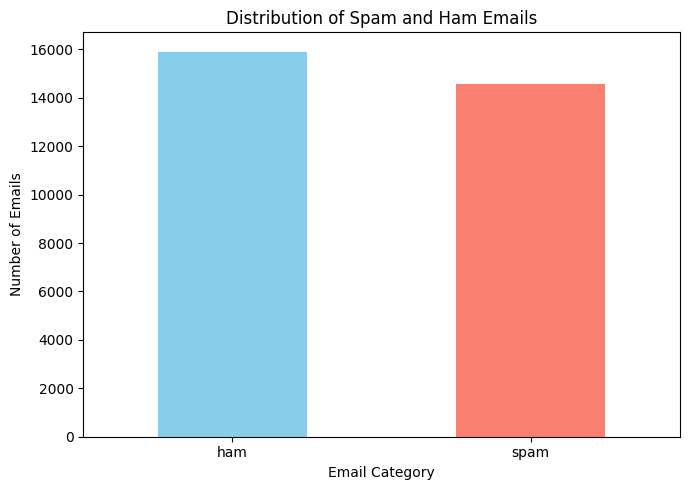

In [21]:
# Visualize Email Spam and Ham Distribution

label_counts = df["label"].value_counts()

plt.figure(figsize=(7, 5))
label_counts.plot(kind="bar", color=["skyblue", "salmon"])

plt.title("Distribution of Spam and Ham Emails")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [6]:
# Separate input features and target labels

X = df["message"]
y = df["label"]

print("Input features (X):")
print(X.head())

print("\nTarget labels (y):")
print(y.head())

print("\nTotal messages:", len(X))

Input features (X):
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: str

Target labels (y):
0     ham
1     ham
2    spam
3     ham
4     ham
Name: label, dtype: str

Total messages: 5169


In [22]:
# Split Email Data into Training and Testing Sets

X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

Training emails: 24369
Testing emails: 6093


In [23]:
# Convert Email Text into Numerical Features

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training email data shape:", X_train_tfidf.shape)
print("Testing email data shape:", X_test_tfidf.shape)
print("Email text converted into numerical features successfully!")

Training email data shape: (24369, 10000)
Testing email data shape: (6093, 10000)
Email text converted into numerical features successfully!


In [24]:
# Train the Email Spam Detection Model

model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("Email Spam Detection model trained successfully!")

Email Spam Detection model trained successfully!


In [25]:
# Evaluate the Email Spam Detection Model

y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="spam")
recall = recall_score(y_test, y_pred, pos_label="spam")
f1 = f1_score(y_test, y_pred, pos_label="spam")

print("Email Spam Detection - Model Evaluation")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Email Spam Detection - Model Evaluation
----------------------------------------
Accuracy:  0.9842
Precision: 0.9789
Recall:    0.9883
F1 Score:  0.9836


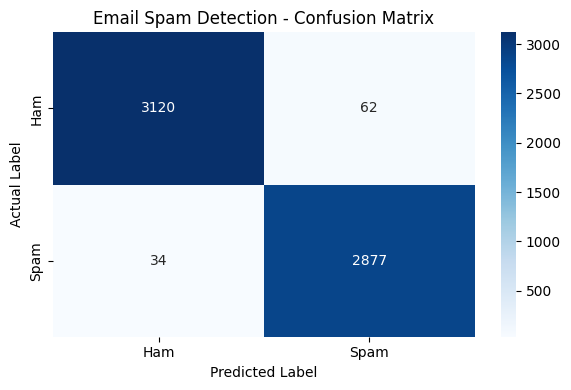

In [26]:
# Confusion Matrix for Email Spam Detection

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Email Spam Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [27]:
# Classification Report for Email Spam Detection

print("Email Spam Detection - Classification Report")
print("-" * 45)

print(classification_report(
    y_test,
    y_pred,
    labels=["ham", "spam"],
    target_names=["Ham (Not Spam)", "Spam"],
    zero_division=0
))

Email Spam Detection - Classification Report
---------------------------------------------
                precision    recall  f1-score   support

Ham (Not Spam)       0.99      0.98      0.98      3182
          Spam       0.98      0.99      0.98      2911

      accuracy                           0.98      6093
     macro avg       0.98      0.98      0.98      6093
  weighted avg       0.98      0.98      0.98      6093



In [28]:
# Save the Email Spam Detection Model

joblib.dump(
    {"model": model, "vectorizer": vectorizer},
    "spam_detection_model.pkl"
)

print("Email spam detection model and vectorizer saved successfully!")

Email spam detection model and vectorizer saved successfully!


In [29]:
# Test the Email Spam Detection Model

sample_emails = [
    "Subject: Congratulations! You won a free prize. Click here to claim your reward.",
    "Subject: Meeting tomorrow. Please review the project report before the meeting.",
    "Subject: Urgent offer! Claim your cash bonus now.",
    "Subject: Project update. The team meeting is scheduled for Monday."
]

sample_tfidf = vectorizer.transform(sample_emails)
sample_predictions = model.predict(sample_tfidf)

for email, prediction in zip(sample_emails, sample_predictions):
    print("Email:", email)
    print("Prediction:", "SPAM" if prediction == "spam" else "NOT SPAM")
    print("-" * 60)

Email: Subject: Congratulations! You won a free prize. Click here to claim your reward.
Prediction: SPAM
------------------------------------------------------------
Email: Subject: Meeting tomorrow. Please review the project report before the meeting.
Prediction: NOT SPAM
------------------------------------------------------------
Email: Subject: Urgent offer! Claim your cash bonus now.
Prediction: SPAM
------------------------------------------------------------
Email: Subject: Project update. The team meeting is scheduled for Monday.
Prediction: NOT SPAM
------------------------------------------------------------


In [30]:
# Save Email Prediction Results to CSV

results_df = pd.DataFrame({
    "Actual_Label": y_test.reset_index(drop=True),
    "Predicted_Label": pd.Series(y_pred).reset_index(drop=True)
})

results_df["Correct_Prediction"] = (
    results_df["Actual_Label"] == results_df["Predicted_Label"]
)

results_df.to_csv("prediction_results.csv", index=False)

print("Email prediction results saved successfully!")
display(results_df.head())

Email prediction results saved successfully!


,Actual_Label,Predicted_Label,Correct_Prediction
0,spam,spam,True
1,ham,ham,True
2,spam,spam,True
3,ham,ham,True
4,spam,spam,True
